# Семинар по теме «Random Forest»


Разберём устройство случайного леса, его гиперпараметры, OOB-оценку и важность признаков. Также проверим фильтрацию обучающих объектов с помощью Isolation Forest.

Переборы `n_estimators`, `max_depth` и `max_features` нужно рассчитать до занятия. На семинаре обсуждаем подготовленные графики и выполняем учебные задания. Время на графиках относится к среде запуска.

## Данные

In [ ]:
!pip install tqdm

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from tqdm.auto import tqdm
from time import time
from sklearn.metrics import f1_score, roc_auc_score

In [ ]:
# Предупреждения sklearn оставляем видимыми.


Используем Rain in Australia. По погодным признакам текущего дня будем предсказывать `RainTomorrow`, наличие дождя на следующий день. Это задача бинарной классификации. Начнём с разведочного анализа данных и подготовки признаков.

In [ ]:
url = "https://rattle.togaware.com/weatherAUS.csv"
df = pd.read_csv(url)

df = df[df['Date'] <= '2026-01-30'].copy()
# Отсутствующая метка не означает отсутствие дождя.
df = df.dropna(subset=['RainTomorrow'])

### Разведочный анализ данных (EDA)

In [ ]:
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,1.0,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0.2,No


**Названия и значения признаков:**

`Location` — название города в Австралии.

`MinTemp` — минимальная температура в течение дня (градусы Цельсия).

`MaxTemp` — максимальная температура в течение дня (градусы Цельсия).

`Rainfall` — количество осадков за день (миллиметры).

`Evaporation` — испарение за день (миллиметры).

`Sunshine` — яркое солнечное освещение за день (часы).

`WindGustDir` — направление самого сильного порыва ветра в течение дня (16 точек компаса).

`WindGustSpeed` — скорость самого сильного порыва ветра в течение дня (километры в час).

`WindDir9am` — направление ветра за 10 минут до 9 часов утра (точки компаса).

`WindDir3pm` — направление ветра за 10 минут до 15 часов (точки компаса).

`WindSpeed9am` — скорость ветра за 10 минут до 9 часов утра (километры в час).

`WindSpeed3pm` — скорость ветра за 10 минут до 15 часов (километры в час).

`Humidity9am` — влажность воздуха в 9 часов утра (проценты).

`Humidity3pm` — влажность воздуха в 15 часов (проценты).

`Pressure9am` — атмосферное давление в 9 часов утра (гектопаскали).

`Pressure3pm` — атмосферное давление в 15 часов (гектопаскали).

`Cloud9am` — доля неба, покрытого облаками, в 9 часов утра (в восьмых долях).

`Cloud3pm` — доля неба, покрытого облаками, в 15 часов (в восьмых долях).

`Temp9am` — температура в 9 часов утра (градусы Цельсия).

`Temp3pm` — температура в 15 часов (градусы Цельсия).

`RainToday` — Yes, если сегодня был дождь. No, если дождя не было.

`RainTomorrow` — `Yes` или `No`, фактический дождь на следующий день. После кодирования используем 1 и 0.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 267317 entries, 0 to 275409
Data columns (total 24 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           267317 non-null  object 
 1   Location       267317 non-null  object 
 2   MinTemp        265971 non-null  float64
 3   MaxTemp        266338 non-null  float64
 4   Rainfall       264742 non-null  float64
 5   Evaporation    113669 non-null  float64
 6   Sunshine       102868 non-null  float64
 7   WindGustDir    249135 non-null  object 
 8   WindGustSpeed  249330 non-null  float64
 9   WindDir9am     247025 non-null  object 
 10  WindDir3pm     255830 non-null  object 
 11  WindSpeed9am   262198 non-null  float64
 12  WindSpeed3pm   257507 non-null  float64
 13  Humidity9am    264462 non-null  float64
 14  Humidity3pm    259287 non-null  float64
 15  Pressure9am    238489 non-null  float64
 16  Pressure3pm    238490 non-null  float64
 17  Cloud9am       147027 non-null  fl

In [ ]:
# Числовые столбцы
numeric = df.select_dtypes(include=['number']).columns
numeric

Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm',
       'Temp9am', 'Temp3pm', 'RISK_MM'],
      dtype='object')

In [ ]:
def nice(ax, title):
    ax.set_title(title, fontsize=14, pad=12)
    ax.grid(alpha=0.25)

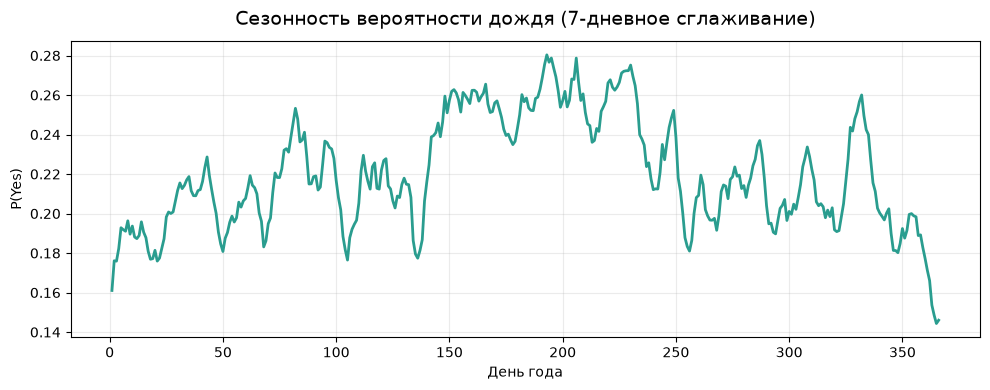

In [ ]:
date = pd.to_datetime(df['Date'])
doy = date.dt.dayofyear
y = (df['RainTomorrow'] == 'Yes').astype(int)

p = y.groupby(doy).mean().rolling(7, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10,4))
ax.plot(p.index, p.values, lw=2, color="#2A9D8F")
ax.set_xlabel('День года'); ax.set_ylabel('P(Yes)')
nice(ax, 'Сезонность вероятности дождя (7-дневное сглаживание)')
plt.tight_layout(); plt.show()

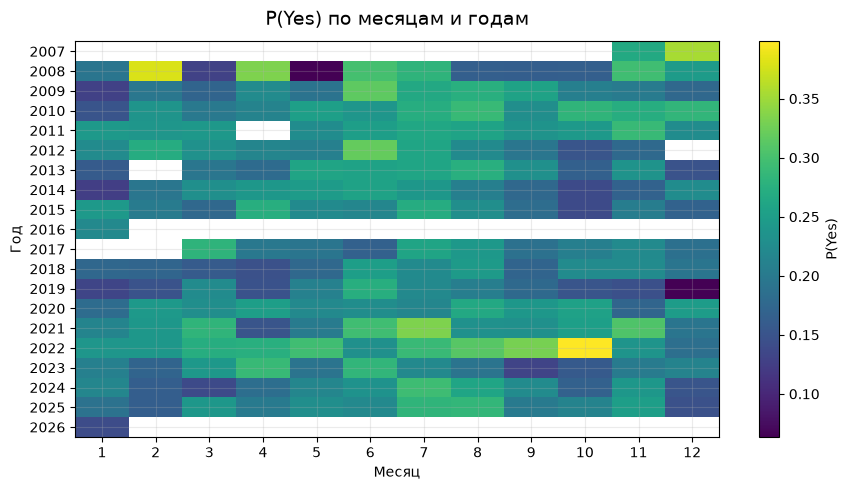

In [ ]:
year = date.dt.year
month = date.dt.month
tab = y.groupby([year, month]).mean().unstack(level=1).sort_index()

fig, ax = plt.subplots(figsize=(9,5))
im = ax.imshow(tab.values, aspect='auto', interpolation='nearest')
ax.set_yticks(range(len(tab.index)), tab.index)
ax.set_xticks(range(12), np.arange(1,13))
ax.set_xlabel('Месяц'); ax.set_ylabel('Год')
nice(ax, 'P(Yes) по месяцам и годам')
fig.colorbar(im, ax=ax, label='P(Yes)')
plt.tight_layout(); plt.show()

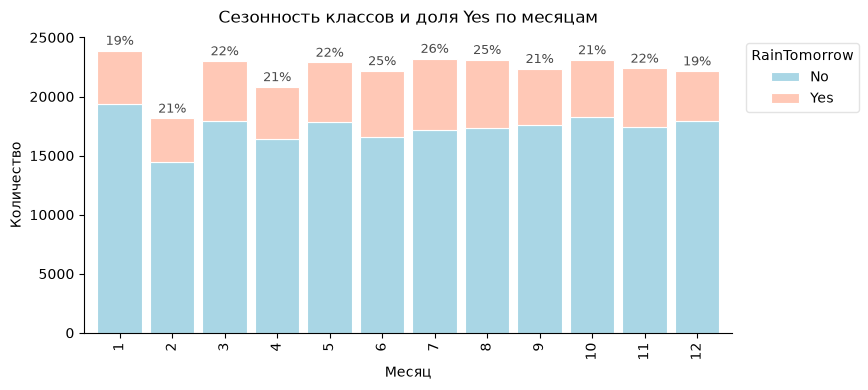

In [ ]:
colors = ["#A9D6E5", "#FFC8B6"]

month_counts = (df.groupby(month)["RainTomorrow"]
                  .value_counts().unstack(fill_value=0)
                  .reindex(columns=["No", "Yes"], fill_value=0))

fig, ax = plt.subplots(figsize=(10, 4))

month_counts.plot(
    kind="bar", stacked=True, ax=ax, width=0.85,
    color=colors, edgecolor="white", linewidth=0.8
)

share_yes = (month_counts["Yes"] / month_counts.sum(1)).fillna(0)
for i, (total, s) in enumerate(zip(month_counts.sum(1), share_yes)):
    ax.text(i, total + total * 0.01, f"{s:.0%}", ha="center", va="bottom",
            fontsize=9, color="#4a4a4a")

ax.set_title("Сезонность классов и доля Yes по месяцам", pad=10)
ax.set_xlabel("Месяц")
ax.set_ylabel("Количество")


ax.legend(
    title="RainTomorrow",
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
    frameon=True, facecolor="white", edgecolor="#dddddd"
)

sns.despine()
plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

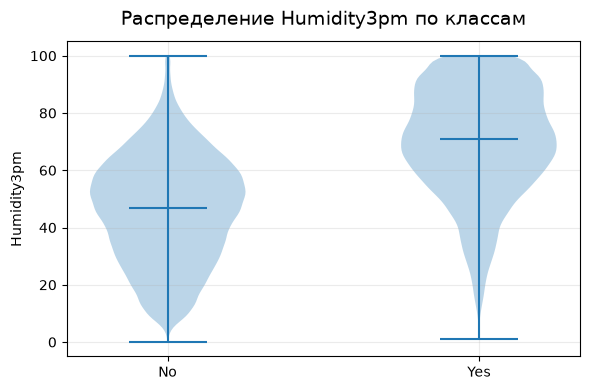

In [ ]:
h3 = df[['Humidity3pm','RainTomorrow']].dropna()
data_no = h3.loc[h3['RainTomorrow']=='No','Humidity3pm'].values
data_yes = h3.loc[h3['RainTomorrow']=='Yes','Humidity3pm'].values

fig, ax = plt.subplots(figsize=(6,4))
ax.violinplot([data_no, data_yes], showmedians=True)
ax.set_xticks([1,2], ['No','Yes'])
ax.set_ylabel('Humidity3pm')
nice(ax, 'Распределение Humidity3pm по классам')
plt.tight_layout(); plt.show()

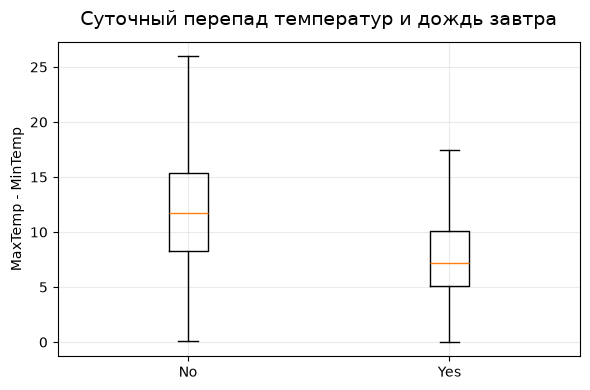

In [ ]:
mxt = df['MaxTemp']; mnt = df['MinTemp']; rt = df['RainTomorrow']
mask = mxt.notna() & mnt.notna() & rt.notna()

delta_no = (mxt[mask]-mnt[mask])[rt[mask]=='No']
delta_yes = (mxt[mask]-mnt[mask])[rt[mask]=='Yes']

fig, ax = plt.subplots(figsize=(6,4))
ax.boxplot([delta_no.values, delta_yes.values], tick_labels=['No','Yes'], showfliers=False)
ax.set_ylabel('MaxTemp - MinTemp')
nice(ax, 'Суточный перепад температур и дождь завтра')
plt.tight_layout(); plt.show()

Корреляции показывают линейные связи числовых признаков. Эти связи нужно учитывать при интерпретации важностей. Сами по себе они не означают, что ансамбль будет работать хуже.


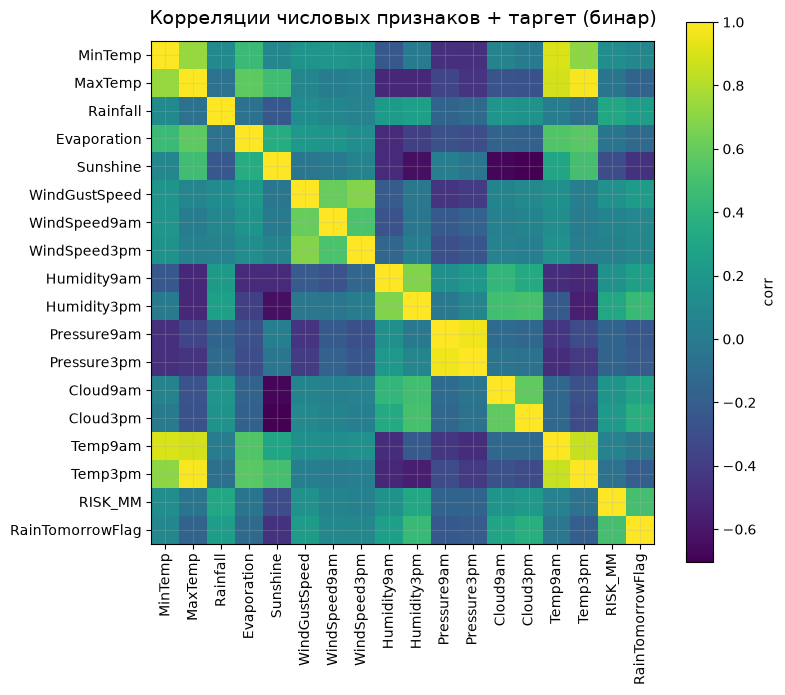

In [ ]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
rt_flag = (df['RainTomorrow'] == 'Yes').astype(int)
corr = pd.concat([df[num_cols], rt_flag.rename('RainTomorrowFlag')], axis=1).corr()

fig, ax = plt.subplots(figsize=(8,7))
im = ax.imshow(corr.values, interpolation='nearest')
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
nice(ax, 'Корреляции числовых признаков + таргет (бинар)')
fig.colorbar(im, ax=ax, label='corr')
plt.tight_layout(); plt.show()

### Препроцессинг

`RISK_MM` содержит количество осадков на следующий день и раскрывает информацию о таргете. Удалим его. Строки без `RainTomorrow` исключим, а пропуски признака `RainToday` заполним по train.


In [ ]:
df = df.drop(columns=['RISK_MM'], errors='ignore')

In [ ]:
# RainToday является признаком, его пропуски заполним по train.
df = df.dropna(subset=['RainTomorrow']).copy()


Выведем число строк и столбцов после удаления пропусков целевой переменной.

In [ ]:
print(f"Форма датасета: {df.shape}")

Форма датасета: (267317, 23)


Посчитаем долю пропусков в каждом столбце.

In [ ]:
na_ratio = df.isnull().mean()
na_features = na_ratio[na_ratio > 0].sort_values(ascending=True) # Снизу вверх — от меньшего к большему

На карте каждая строка соответствует наблюдению. Жёлтым отмечены пропуски, тёмно-синим заполненные значения. Посмотрим, встречаются ли пропуски одних признаков одновременно.

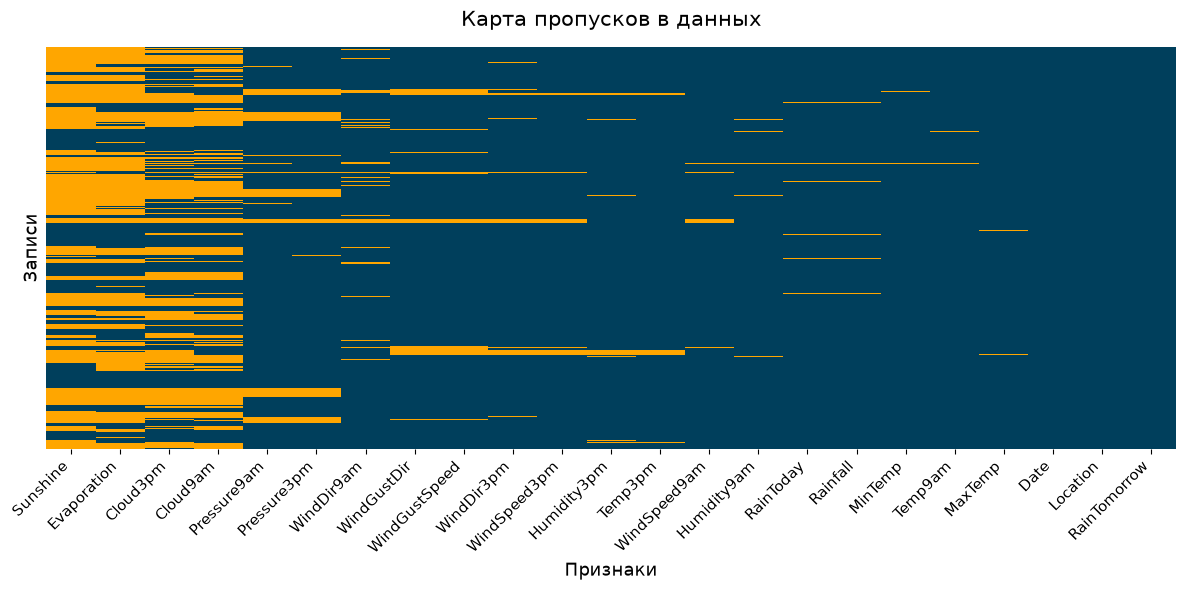

In [ ]:
# Сортируем колонки по доле NaN (сначала больше пропусков)
nan_order = df.isna().mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12,6))
sns.heatmap(
    df[nan_order].isnull(),
    cmap=['#003f5c', '#ffa600'],  # Тёмно-синий означает «есть данные», жёлтый — пропуск
    cbar=False,
    yticklabels=False,
    ax=ax
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=11)
ax.set_xlabel('Признаки', fontsize=13)
ax.set_ylabel('Записи', fontsize=13)
ax.set_title('Карта пропусков в данных', fontsize=15, pad=15)
plt.tight_layout()
plt.show()

Посчитаем суммарно, сколько пропусков во всём датасете.

In [ ]:
df.isnull().sum().sum()

np.int64(731538)

Сначала выделим train и validation со стратификацией по таргету. Затем оценим средние числовых признаков и моды категорий только по train, отдельно для каждого региона. Если в регионе нет значения, используем статистику всего train.

Эти же значения применим к validation. В следующих опытах разбиение остаётся фиксированным. Случайный сплит здесь нужен для учебного сравнения. Для прогноза будущей погоды понадобилась бы проверка по времени.


In [ ]:
train_idx, valid_idx = train_test_split(
    df.index, test_size=0.3, random_state=42, stratify=df['RainTomorrow'])
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.difference(
    ['Date', 'Location', 'RainTomorrow']).tolist()
train_raw = df.loc[train_idx].copy()

for col in numeric_cols:
    regional = train_raw.groupby('Location')[col].mean()
    df[col] = df[col].fillna(df['Location'].map(regional)).fillna(train_raw[col].mean())

for col in cat_cols:
    def mode_or_nan(values):
        modes = values.mode()
        return modes.iloc[0] if len(modes) else np.nan
    regional = train_raw.groupby('Location')[col].agg(mode_or_nan)
    fallback = mode_or_nan(train_raw[col])
    df[col] = df[col].fillna(df['Location'].map(regional)).fillna(fallback)


Проверим, избавились ли мы от всех пропусков.

In [ ]:
df.isnull().sum().sum()

np.int64(0)

Добавим из `Date` год наблюдения `Year` и сезон `Season`. Сезоны зададим для Южного полушария. Это даст модели информацию о времени года.

In [ ]:
# 1. Приводим к datetime
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')

# 2. Извлекаем год
df['Year'] = df['Date'].dt.year

# 3. Функция для определения сезона (южное полушарие)
def month_to_season(month):
    if month in (12, 1, 2):
        return 'Summer'
    elif month in (3, 4, 5):
        return 'Autumn'
    elif month in (6, 7, 8):
        return 'Winter'
    else:
        return 'Spring'

# 4. Применяем к номеру месяца
df['Season'] = df['Date'].dt.month.map(month_to_season)

In [ ]:
df.head(3)

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Year,Season
0,2008-12-01,Albury,13.4,22.9,0.6,5.498277,7.633724,W,44.0,W,...,1007.7,1007.1,8.00000,5.226705,16.9,21.8,No,No,2008,Summer
1,2008-12-02,Albury,7.4,25.1,0.0,5.498277,7.633724,WNW,44.0,NNW,...,1010.6,1007.8,6.23202,5.226705,17.2,24.3,No,No,2008,Summer
2,2008-12-03,Albury,12.9,25.7,0.0,5.498277,7.633724,WSW,46.0,W,...,1007.6,1008.7,6.23202,2.000000,21.0,23.2,No,No,2008,Summer


Теперь `Date` можно удалить.

In [ ]:
df.drop(columns = 'Date',inplace=True)

Преобразуем категории в бинарные признаки. Набор категорий определяем по train и применяем его к validation. Неизвестные категории получат нули во всех индикаторах. Для бинарного таргета заранее известны два значения: `No` и `Yes`.


In [ ]:
for col in df.select_dtypes(include=['object', 'category']).columns:
    categories = ['No', 'Yes'] if col == 'RainTomorrow' else sorted(df.loc[train_idx, col].dropna().unique())
    df[col] = pd.Categorical(df[col], categories=categories)
df = pd.get_dummies(df, dtype=int, drop_first=True)
df.head(3)


,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,RainToday_Yes,RainTomorrow_Yes,Season_Spring,Season_Summer,Season_Winter
0,13.4,22.9,0.6,5.498277,7.633724,44.0,20.0,24.0,71.0,22.0,...,0,0,0,1,0,0,0,0,1,0
1,7.4,25.1,0.0,5.498277,7.633724,44.0,4.0,22.0,44.0,25.0,...,0,0,0,0,1,0,0,0,1,0
2,12.9,25.7,0.0,5.498277,7.633724,46.0,19.0,26.0,38.0,30.0,...,0,0,0,0,1,0,0,0,1,0


In [ ]:
df.shape

(267317, 115)

In [ ]:
y = df['RainTomorrow_Yes']

Посмотрим, как распределена целевая переменная и есть ли значительный дисбаланс классов.

In [ ]:
y.mean()

np.float64(0.2204274325987498)

Используем то же разбиение, которое выделили перед заполнением пропусков. Validation служит для сравнения параметров и методов. Ошибку на ней после выбора модели нельзя считать независимой итоговой оценкой.


In [ ]:
df.rename({'RainToday_Yes':'RainToday','RainTomorrow_Yes':'RainTomorrow'},axis=1,inplace=True)

In [ ]:
X_train = df.loc[train_idx].drop(columns=['RainTomorrow']).copy()
X_valid = df.loc[valid_idx].drop(columns=['RainTomorrow']).copy()
y_train = df.loc[train_idx, 'RainTomorrow'].copy()
y_valid = df.loc[valid_idx, 'RainTomorrow'].copy()
print(f'train: {X_train.shape}, validation: {X_valid.shape}')


train: (187121, 114), validation: (80196, 114)


Деревья обычно не требуют стандартизации: положительное линейное изменение масштаба сохраняет порядок значений и допустимых разбиений. Здесь сохраняем общую подготовку числовых столбцов. Скейлер обучаем по train и применяем к validation.

In [ ]:
numeric = pd.Index(numeric_cols)
numeric


Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm',
       'Temp9am', 'Temp3pm'],
      dtype='object')

In [ ]:
# Инициализируем скейлер
scaler = StandardScaler()

# Fit только на train
X_train[numeric] = scaler.fit_transform(X_train[numeric])

# Transform на валидации с теми же μ и σ
X_valid[numeric] = scaler.transform(X_valid[numeric])

In [ ]:
X_train.head()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,RainToday,Season_Spring,Season_Summer,Season_Winter
86782,-0.607825,-0.068005,0.220884,-0.598162,-0.088770,0.306711,1.138671,0.639232,-1.039331,-0.896461,...,0,0,0,0,0,0,1,0,1,0
127316,0.636593,0.986223,-0.272128,1.295820,1.739175,-0.382375,-0.118279,0.873276,0.049200,-0.367306,...,1,0,0,0,0,0,0,0,1,0
161186,0.745479,1.183012,-0.272128,0.173460,0.484201,-0.229245,-1.146692,-0.179924,-0.728322,0.739109,...,0,0,0,0,0,0,0,1,0,0
175905,0.885476,-0.574035,-0.201698,-0.002512,-0.003680,-0.382375,-0.346815,0.054121,0.774887,1.220159,...,0,0,0,0,0,0,0,0,0,1
96700,-1.821132,-1.389305,-0.248652,-0.002512,-0.003680,0.306711,0.110258,-0.648013,-0.158139,-0.511621,...,0,0,0,0,0,0,0,0,0,1


In [ ]:
y_valid.head()

131196    0
94210     0
182982    0
17556     0
201946    0
Name: RainTomorrow, dtype: int64

## Случайный лес (Random Forest)


Повторим теорию.

> **Случайный лес** (англ. random forest) — расширение бэггинга с дополнительной рандомизацией признаков на каждом узле.

Алгоритм добавляет случайную подвыборку признаков, когда строится каждое разбиение в дереве.

Окончательное предсказание случайного леса совпадает с формулой бэггинга, но с учётом случайных параметров $\Theta_i$ выбора признаков.

Для регрессии ответы деревьев усредняются:

$$a(x) = \frac{1}{M}\sum_{i=1}^{M} b_i(x, \Theta_i).$$

Для классификации есть два стандартных варианта.

1) *Hard voting.* Каждое дерево голосует меткой класса, итог — самый частый ответ:

$$a(x) = \mathrm{mode}\bigl\{ b_1(x, \Theta_1),\, b_2(x, \Theta_2),\, \ldots,\, b_M(x, \Theta_M) \bigr\}.$$

2) *Soft voting.* Усредняются вероятности классов по деревьям, после чего выбирается класс с наибольшей средней вероятностью:

$$a(x) = \arg\max_{y \in \mathcal{Y}} \frac{1}{M}\sum_{i=1}^{M} p_i(y \mid x, \Theta_i),$$

где $p_i(y \mid x, \Theta_i)$ — вероятность класса $y$, которую дерево $b_i$ выдаёт в листе, содержащем $x$.

`RandomForestClassifier` в sklearn усредняет вероятности деревьев, то есть использует Soft Voting.


### Метрика качества

ROC-AUC оценивает ранжирование положительного класса и не требует выбора порога. Постоянный прогноз получает ROC-AUC 0.5, даже если accuracy высока из-за дисбаланса.

ROC-AUC не описывает качество конкретного порога и долю верных тревог. В этом семинаре используем её для сравнения моделей на одной validation.


### Сравнение Bagging и Random forest

Бэггинг особенно полезен для неустойчивых моделей. Глубокие деревья подходят для такого сравнения. Сначала оценим одиночное дерево, затем ансамбли.


Случай с **одиночным** неограниченным деревом решений:

In [ ]:
base_tree = DecisionTreeClassifier(random_state=42, class_weight='balanced')
base_tree.fit(X_train, y_train)
auc_tree_train = roc_auc_score(y_train, base_tree.predict_proba(X_train)[:, 1])
auc_tree_valid = roc_auc_score(y_valid, base_tree.predict_proba(X_valid)[:, 1])
print(f'Неограниченное дерево: train ROC-AUC={auc_tree_train:.4f}, validation ROC-AUC={auc_tree_valid:.4f}')


Неограниченное дерево: train ROC-AUC=1.0000, validation ROC-AUC=0.7038


In [ ]:
# Проверим, какая у неограниченного дерева глубина
tree_depth = base_tree.get_depth()
tree_depth

51

Ограничим максимальную глубину дерева и сравним ROC-AUC на validation. Такое ограничение задаётся до построения дерева и называется предварительной обрезкой (pre-pruning).

In [ ]:
valid_scores = []
for d in range(1, tree_depth, 4):
    base_tree = DecisionTreeClassifier(max_depth=d, random_state=42, class_weight='balanced')
    base_tree.fit(X_train, y_train)
    y_proba = base_tree.predict_proba(X_valid)[:,1]
    valid_scores.append(roc_auc_score(y_valid, y_proba))

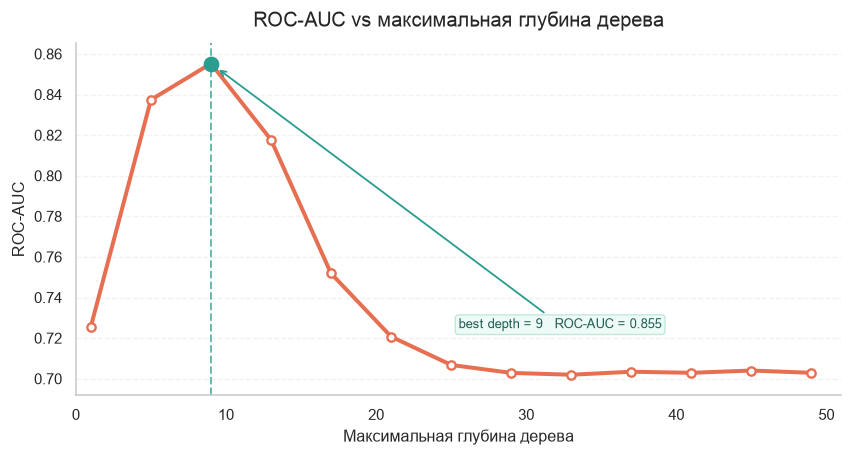

In [ ]:
sns.set_theme(style="whitegrid", context="paper")

depths = np.arange(1, tree_depth, 4)
scores = np.array(valid_scores)

# лучший depth
best_idx = scores.argmax()
best_d, best_s = depths[best_idx], scores[best_idx]

fig, ax = plt.subplots(figsize=(7.2, 3.9), dpi=120)

ax.plot(
    depths, scores,
    color="#e76f51", lw=2.4,
    marker="o", ms=5, mfc="white", mec="#e76f51", mew=1.4
)

ax.scatter(best_d, best_s, s=75, color="#2a9d8f", zorder=5)
ax.axvline(best_d, ls="--", lw=1.2, color="#2a9d8f", alpha=0.7)


ax.annotate(
    f"best depth = {best_d}   ROC-AUC = {best_s:.3f}",
    xy=(best_d, best_s),
    xytext=(0.5, 0.2), textcoords='axes fraction',
    ha="left", va="center",
    fontsize=8, color="#1f5f55",
    bbox=dict(boxstyle="round,pad=0.25", fc="#eefaf6", ec="#bfe8dc"),
    arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=1.1, shrinkB=6),
    zorder=6
)

ax.set_title("ROC-AUC vs максимальная глубина дерева", fontsize=12, pad=10)
ax.set_xlabel("Максимальная глубина дерева")
ax.set_ylabel("ROC-AUC")

ax.set_xlim(depths.min() - 1, depths.max() + 2)
ax.set_ylim(scores.min() - 0.01, scores.max() + 0.01)

ax.grid(axis="y", ls="--", alpha=0.25)
ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
# Максимальный ROC-AUC
valid_scores[best_idx]

0.8552703764897128

Переменные `best_d` и `best_s` показывают лучшую проверенную глубину и её ROC-AUC на validation. Это результат поиска в заданной сетке, а не максимально возможное качество одиночного дерева.


Сравним бэггинг и случайный лес на валидационной выборке. Сначала обучим каждый ансамбль с тремя неограниченными деревьями решений.

In [ ]:
# Берём неограниченное дерево как базис
base_tree = DecisionTreeClassifier(random_state=42, class_weight='balanced')

In [ ]:
bagging_classifier = BaggingClassifier(
        estimator=base_tree,
        n_estimators=3,
        max_samples=1.0,
        bootstrap=True,
        oob_score=False,
        n_jobs=-1,
        random_state=42)

rf_classifier = RandomForestClassifier(
        n_estimators=3,
        criterion='gini',
        max_depth=None,
        max_samples=1.0,
        max_features='sqrt',
        bootstrap=True,
        oob_score=False,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42)

bagging_classifier.fit(X_train, y_train)
rf_classifier.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"max_samples max_samples: int or float, default=NoneIf bootstrap is True, the number of samples to draw from Xto train each base estimator.- If None (default), then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples... versionadded:: 0.22.. versionchanged:: 1.9 Float `max_samples` is relative to `sample_weight.sum()` instead of `X.shape[0]` for weighted samples.",1.0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are th

In [ ]:
y_proba = bagging_classifier.predict_proba(X_valid)[:,1]
print('Bagging ROC-AUC:', roc_auc_score(y_valid, y_proba))

y_proba = rf_classifier.predict_proba(X_valid)[:,1]
print('Random Forest ROC-AUC:', roc_auc_score(y_valid, y_proba))

Bagging ROC-AUC: 0.7912624859038948
Random Forest ROC-AUC: 0.8060577740728192


Сравни напечатанный ROC-AUC ансамблей с `auc_tree_valid` одиночного неограниченного дерева. Все прогнозы оценены на одной validation.


Теперь сравни эти ансамбли с `best_s` ограниченного одиночного дерева. В ансамблях пока только три дерева. Проверим, как меняются качество и время при увеличении их числа.


####  `n_estimators`

In [ ]:
# Снова неограниченное дерево
base_tree = DecisionTreeClassifier(random_state=42, class_weight='balanced')

Увеличим количество базисных деревьев. Пока возьмём `n_estimators` от 1 до 41, так как обучение на большем количестве деревьев занимает много времени.

Далее мы разберём, как ускорить обучение, и будем обучаться уже на большем количестве базисов.

In [ ]:
# Тяжёлый перебор. Рассчитать до занятия.
roc_auc_scores = []
train_predict_times = []
roc_auc_scores_rf = []
train_predict_times_rf = []

# Посмотрим на качество ансамблей для случаев от 1 до 41 базовых деревьев
for n_estimators in tqdm(range(1, 42, 4)):

    bagging_classifier = BaggingClassifier(
        estimator=base_tree,
        n_estimators=n_estimators,
        n_jobs=-1,
        random_state=42
    )

    rf_classifier = RandomForestClassifier(
        n_estimators=n_estimators,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42)

    # Замеряем время обучения для Bagging
    start_time = time()
    bagging_classifier.fit(X_train, y_train)
    y_proba = bagging_classifier.predict_proba(X_valid)[:,1]
    end_time = time()

    # Замеряем время обучения для RF
    start_time_rf = time()
    rf_classifier.fit(X_train, y_train)
    y_proba_rf = rf_classifier.predict_proba(X_valid)[:,1]
    end_time_rf = time()

    # Сохраняем метрики и время
    roc_auc_scores.append(roc_auc_score(y_valid, y_proba))
    train_predict_times.append(end_time - start_time)

    roc_auc_scores_rf.append(roc_auc_score(y_valid, y_proba_rf))
    train_predict_times_rf.append(end_time_rf - start_time_rf)

Локальная проверка: 2 рабочих процессов. Сравнивайте время внутри графика. Для сравнения времени между графиками нужна одинаковая среда.


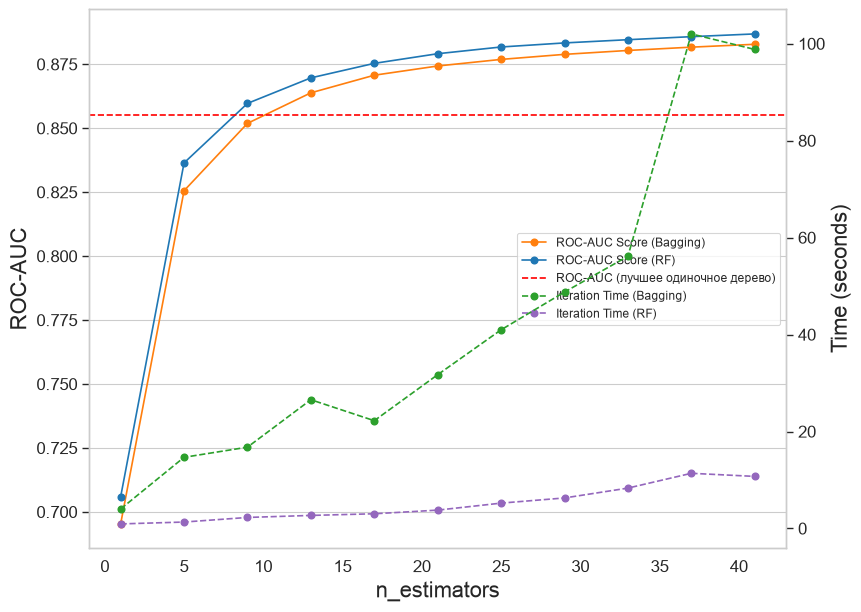

In [ ]:
# Строим график
n_estimators_values = list(range(1, 42, 4))

plt.figure(figsize=(9, 7))

ax1 = plt.gca()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax1.plot(n_estimators_values, roc_auc_scores, label='ROC-AUC Score (Bagging)', marker='o', color='tab:orange')
ax1.plot(n_estimators_values, roc_auc_scores_rf, label='ROC-AUC Score (RF)', marker='o', color='tab:blue')

ax1.axhline(y=best_s, linestyle='--',color='red', label='ROC-AUC (лучшее одиночное дерево)')

ax1.set_xlabel('n_estimators', fontsize=16)
ax1.set_ylabel('ROC-AUC', fontsize=16)
ax1.tick_params(axis='y')
plt.grid(axis='x')

ax2 = ax1.twinx()
plt.yticks(fontsize=12)

ax2.plot(n_estimators_values, train_predict_times, label='Iteration Time (Bagging)',
         linestyle='dashed', marker='o', color='tab:green')
ax2.plot(n_estimators_values, train_predict_times_rf, label='Iteration Time (RF)',
         linestyle='dashed', marker='o', color='tab:purple')

ax2.set_ylabel('Time (seconds)', fontsize=16)

ax2.tick_params(axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.grid()
plt.show()

Сравни ансамбли с горизонтальной линией лучшего одиночного дерева из предыдущего поиска. Все модели оцениваются на одних объектах. В бэггинге и лесу здесь одинаково задан `class_weight='balanced'`. Напечатанные и построенные метрики относятся к этому разбиению.


При увеличении числа деревьев качество часто стабилизируется, но ROC-AUC на конечной валидации не обязан расти монотонно. Каждый новый ансамбль с нуля повторяет обучение уже проверенных деревьев. Используем `warm_start`, чтобы в одном опыте добавлять только новые деревья.


#### `n_estimators` & `warm_start`

При `warm_start=True` повторный `.fit()` сохраняет имеющиеся деревья и добавляет новые при увеличении `n_estimators`. В этом опыте фиксируем данные, порядок строк и остальные настройки. Уже построенные деревья не переобучаются.

При `warm_start=False` вызов `.fit()` строит ансамбль заново. Время одной итерации с `warm_start` включает обучение добавленных деревьев и прогнозирование всем текущим ансамблем.


При `warm_start=True` увеличим число деревьев от 12 до 180. На каждой итерации добавляются 12 новых деревьев, а уже обученные сохраняются.

In [ ]:
# Тяжёлый перебор. Рассчитать до занятия.
roc_auc_scores_warm = []
train_predict_times_warm = []
roc_auc_scores_rf_warm = []
train_predict_times_rf_warm = []

bagging_classifier = BaggingClassifier(
        estimator=base_tree,
        n_estimators=12,
        warm_start=True, # Переиспользуем уже обученные деревья
        n_jobs=-1,
        random_state=42
    )

rf_classifier = RandomForestClassifier(
    n_estimators=12,
    warm_start=True,
        class_weight='balanced',
    n_jobs=-1,
    random_state=42)

# Попробуем теперь обучаться на 180 базисах
for n in tqdm(range(12, 192, 12)):
    bagging_classifier.set_params(n_estimators=n)
    rf_classifier.set_params(n_estimators=n)


    start_time = time()
    bagging_classifier.fit(X_train, y_train)
    y_proba = bagging_classifier.predict_proba(X_valid)[:, 1]
    end_time = time()

    start_time_rf = time()
    rf_classifier.fit(X_train, y_train)
    y_proba_rf = rf_classifier.predict_proba(X_valid)[:, 1]
    end_time_rf = time()

    roc_auc_scores_warm.append(roc_auc_score(y_valid, y_proba))
    train_predict_times_warm.append(end_time - start_time)

    roc_auc_scores_rf_warm.append(roc_auc_score(y_valid, y_proba_rf))
    train_predict_times_rf_warm.append(end_time_rf - start_time_rf)



Локальная проверка: 6 рабочих процессов. Сравнивайте время внутри графика. Для сравнения времени между графиками нужна одинаковая среда.


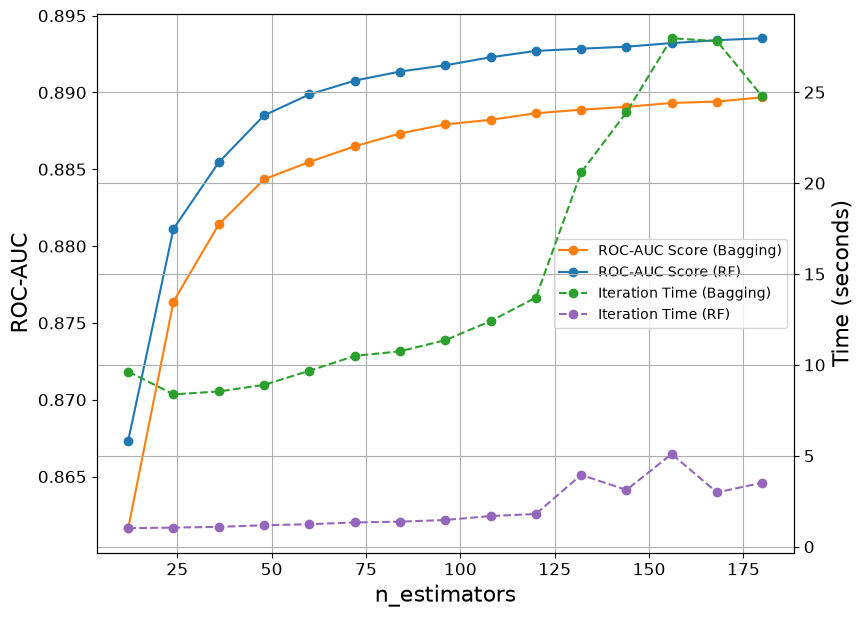

In [ ]:
# Строим график
n_estimators_values = list(range(12, 192, 12))

plt.figure(figsize=(9, 7))

ax1 = plt.gca()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax1.plot(n_estimators_values, roc_auc_scores_warm, label='ROC-AUC Score (Bagging)', marker='o', color='tab:orange')
ax1.plot(n_estimators_values, roc_auc_scores_rf_warm, label='ROC-AUC Score (RF)', marker='o', color='tab:blue')
ax1.set_xlabel('n_estimators', fontsize=16)
ax1.set_ylabel('ROC-AUC', fontsize=16)
ax1.tick_params(axis='y')
plt.grid(axis='x')

ax2 = ax1.twinx()
plt.yticks(fontsize=12)

ax2.plot(n_estimators_values, train_predict_times_warm, label='Iteration Time (Bagging)',
         linestyle='dashed', marker='o', color='tab:green')
ax2.plot(n_estimators_values, train_predict_times_rf_warm, label='Iteration Time (RF)',
         linestyle='dashed', marker='o', color='tab:purple')


ax2.set_ylabel('Time (seconds)', fontsize=16)

ax2.tick_params(axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.grid()
plt.show()

**Вопрос.** Как увеличение числа деревьев влияет на ROC-AUC и время итерации при warm_start? Когда дальнейшее увеличение становится невыгодным?

**Ответ.** В проверенном запуске качество в целом увеличивается с числом деревьев, хотя отдельные шаги могут давать колебания, а RF имеет более высокий ROC-AUC. После примерно 120 деревьев прибавки становятся небольшими. Это ориентир для данного разбиения, а не универсальный оптимум. При каждой итерации обучаются 12 новых деревьев, но прогноз строится всеми деревьями, поэтому время итерации может увеличиваться. Дальнейший выбор зависит от требуемой стабильности и вычислительного бюджета.


#### `max_depth`

Ограничение глубины меняет гибкость и время работы базовых деревьев. Проверим глубины 1, 6, 11, …, 51 при фиксированных 30 базисах.

Глубина одиночного неограниченного дерева напечатана в `tree_depth`. Деревья ансамбля могут иметь другие глубины из-за бутстрэпа и рандомизации признаков.


##### Задание 1

- Построй ансамбли бэггинга и случайного леса над деревьями решений глубиной от 1 до 51 (включительно) с шагом 5. Количество базисных деревьев для обоих ансамблей установи на уровне 30.

- Для каждого шага в цикле измерь валидационный ROC-AUC получившихся ансамблей.

- Для каждого ансамбля отдельно замерь суммарное время `fit` и `predict_proba` на каждом шаге цикла.

- Все метрики качества сохрани в массивах `roc_auc_scores_depth` и `roc_auc_scores_rf_depth` (для бэггинга и леса соответственно). Время обучения/предсказания сохрани в массивах `train_predict_times_depth` и `train_predict_times_rf_depth`.

- Построй график зависимости ROC-AUC и времени обучения/предсказания обоих ансамблей от глубины базисных деревьев.
Для обоих ансамблей используй seed 42 и `class_weight='balanced'` у базовых деревьев. Бэггинг использует все признаки, лес `max_features='sqrt'`. Остальные настройки оставь фиксированными.


**Заготовка задания. Решение в следующем кодовом блоке.**

```python
# Тяжёлый перебор. Рассчитать до занятия.
roc_auc_scores_depth = []
train_predict_times_depth = []
roc_auc_scores_rf_depth = []
train_predict_times_rf_depth = []

for i in tqdm(range(1, 54, 5)):

    base_tree = # your code here

    bagging_classifier = # BaggingClassifier(...)

    rf_classifier = # RandomForestClassifier(...)

    # Замеряем время обучения для Bagging
    start_time = time()
    # .fit(...)
    # .predict_proba(...)
    end_time = time()

    # Замеряем время обучения для RF
    start_time_rf = time()
    # .fit(...)
    # .predict_proba(...)
    end_time_rf = time()

    # Сохраняем метрики и время
    roc_auc_scores_depth.append(roc_auc_score(y_valid, y_proba))
    train_predict_times_depth.append(end_time - start_time)

    roc_auc_scores_rf_depth.append(roc_auc_score(y_valid, y_proba_rf))
    train_predict_times_rf_depth.append(end_time_rf - start_time_rf)
```


###### Решение

In [ ]:
# Тяжёлый перебор. Рассчитать до занятия.
roc_auc_scores_depth = []
train_predict_times_depth = []
roc_auc_scores_rf_depth = []
train_predict_times_rf_depth = []

for i in tqdm(range(1, 54, 5)):

    base_tree = DecisionTreeClassifier(max_depth=i, random_state=42, class_weight='balanced')

    bagging_classifier = BaggingClassifier(
        estimator=base_tree,
        n_estimators=30,
        n_jobs=-1,
        random_state=42
    )

    rf_classifier = RandomForestClassifier(
        n_estimators=30,
        max_depth=i,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42)

    # Замеряем время обучения для Bagging
    start_time = time()
    bagging_classifier.fit(X_train, y_train)
    y_proba = bagging_classifier.predict_proba(X_valid)[:,1]
    end_time = time()

    # Замеряем время обучения для RF
    start_time_rf = time()
    rf_classifier.fit(X_train, y_train)
    y_proba_rf = rf_classifier.predict_proba(X_valid)[:,1]
    end_time_rf = time()

    # Сохраняем метрики и время
    roc_auc_scores_depth.append(roc_auc_score(y_valid, y_proba))
    train_predict_times_depth.append(end_time - start_time)

    roc_auc_scores_rf_depth.append(roc_auc_score(y_valid, y_proba_rf))
    train_predict_times_rf_depth.append(end_time_rf - start_time_rf)

Полная сетка, локальный проверочный запуск, n_jobs=6. Время зависит от среды.


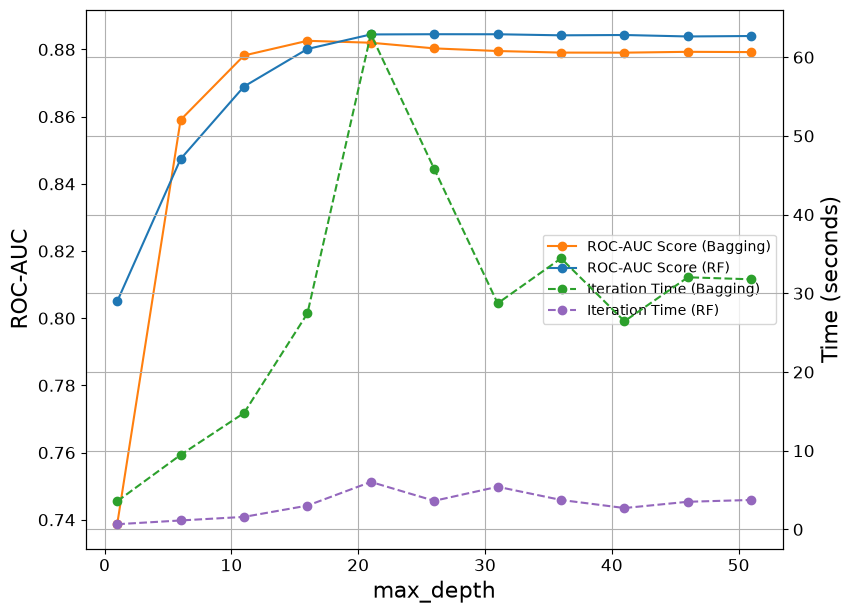

In [ ]:
# Строим график
n_estimators_values = list(range(1, 54, 5))

plt.figure(figsize=(9, 7))

ax1 = plt.gca()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax1.plot(n_estimators_values, roc_auc_scores_depth, label='ROC-AUC Score (Bagging)', marker='o', color='tab:orange')
ax1.plot(n_estimators_values, roc_auc_scores_rf_depth, label='ROC-AUC Score (RF)', marker='o', color='tab:blue')
ax1.set_xlabel('max_depth', fontsize=16)
ax1.set_ylabel('ROC-AUC', fontsize=16)
ax1.tick_params(axis='y')
plt.grid(axis='x')

ax2 = ax1.twinx()
plt.yticks(fontsize=12)

ax2.plot(n_estimators_values, train_predict_times_depth, label='Iteration Time (Bagging)',
         linestyle='dashed', marker='o', color='tab:green')
ax2.plot(n_estimators_values, train_predict_times_rf_depth, label='Iteration Time (RF)',
         linestyle='dashed', marker='o', color='tab:purple')


ax2.set_ylabel('Time (seconds)', fontsize=16)

ax2.tick_params(axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.grid()
plt.show()

##### Выводы

На сохранённом графике качество обоих ансамблей заметно растёт до глубин 16–21. Далее ROC-AUC леса остаётся около 0.884, а бэггинга немного снижается, примерно до 0.879. Увеличение глубины после этого участка не даёт выигрыша на данной validation.

В этом запуске лес работает быстрее бэггинга. При близком качестве ограничение глубины позволяет уменьшить размер деревьев. Колебания измеренного времени зависят также от параллельного выполнения и нагрузки среды.

#### `max_features`

В случайном лесе `max_features` ограничивает число признаков-кандидатов на каждом разбиении. В `BaggingClassifier` этот параметр выбирает набор признаков для всего базового дерева.

Уменьшение числа доступных признаков может сделать модели менее похожими, но также лишить отдельный базис полезных разбиений. Сравним итоговый ROC-AUC и время. Формула дисперсии среднего сама по себе не устанавливает, какой параметр даст лучший результат.

В sklearn поиск может проверить дополнительные признаки, если исходные кандидаты не дают допустимого разбиения. [Описание параметра](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).


In [ ]:
# Полная сетка требует долгого расчёта. Подготовить график до занятия.
roc_auc_scores_feats = []
train_predict_times_feats = []
roc_auc_scores_rf_feats = []
train_predict_times_rf_feats = []

base_tree = DecisionTreeClassifier(random_state=42, class_weight='balanced')

for i in tqdm(range(1, X_train.shape[1] + 1, 10)):

    bagging_classifier = BaggingClassifier(
        estimator=base_tree,
        n_estimators=100,
        max_features=i,
        n_jobs=-1,
        random_state=42
    )

    rf_classifier = RandomForestClassifier(
        n_estimators=100,
        max_features=i,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42)

    # Замеряем время обучения для Bagging
    start_time = time()
    bagging_classifier.fit(X_train, y_train)
    y_proba = bagging_classifier.predict_proba(X_valid)[:,1]
    end_time = time()

    # Замеряем время обучения для RF
    start_time_rf = time()
    rf_classifier.fit(X_train, y_train)
    y_proba_rf = rf_classifier.predict_proba(X_valid)[:,1]
    end_time_rf = time()

    # Сохраняем метрики и время
    roc_auc_scores_feats.append(roc_auc_score(y_valid, y_proba))
    train_predict_times_feats.append(end_time - start_time)

    roc_auc_scores_rf_feats.append(roc_auc_score(y_valid, y_proba_rf))
    train_predict_times_rf_feats.append(end_time_rf - start_time_rf)

Полная сетка, локальный проверочный запуск, n_jobs=6. Время зависит от среды.


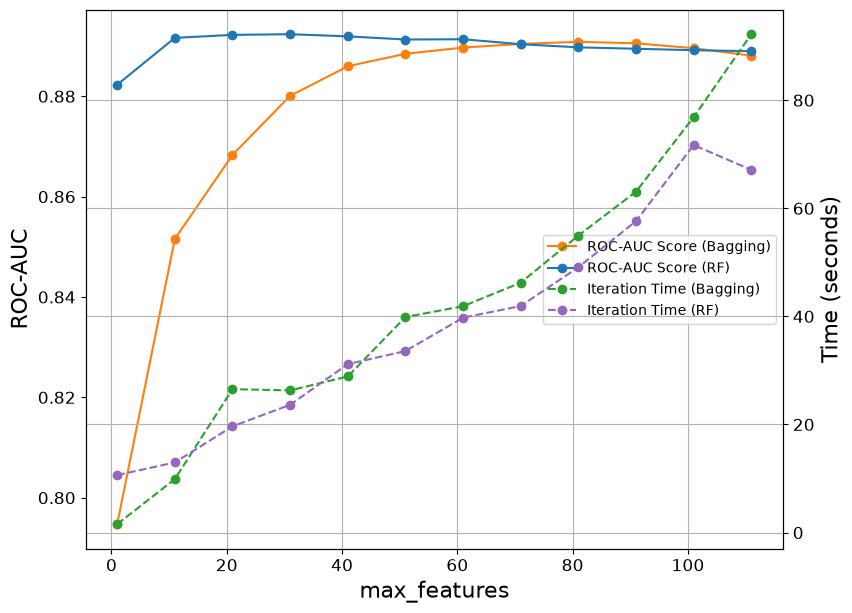

In [ ]:
# Строим график
n_estimators_values = list(range(1, X_train.shape[1] + 1, 10))

plt.figure(figsize=(9, 7))

ax1 = plt.gca()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax1.plot(n_estimators_values, roc_auc_scores_feats, label='ROC-AUC Score (Bagging)', marker='o', color='tab:orange')
ax1.plot(n_estimators_values, roc_auc_scores_rf_feats, label='ROC-AUC Score (RF)', marker='o', color='tab:blue')
ax1.set_xlabel('max_features', fontsize=16)
ax1.set_ylabel('ROC-AUC', fontsize=16)
ax1.tick_params(axis='y')
plt.grid(axis='x')


ax2 = ax1.twinx()
plt.yticks(fontsize=12)

ax2.plot(n_estimators_values, train_predict_times_feats, label='Iteration Time (Bagging)',
         linestyle='dashed', marker='o', color='tab:green')
ax2.plot(n_estimators_values, train_predict_times_rf_feats, label='Iteration Time (RF)',
         linestyle='dashed', marker='o', color='tab:purple')


ax2.set_ylabel('Time (seconds)', fontsize=16)

ax2.tick_params(axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.grid()
plt.show()

**Вопрос.** Какие выводы можешь сделать по этому графику?



**Ответ.** На сохранённом графике ROC-AUC леса достигает около 0.892 уже при 11 признаках на узел и дальше меняется мало. Бэггинг при одном признаке на дерево даёт около 0.795, а при 61–81 признаке приближается к 0.89. Время в целом растёт с числом признаков.

В лесу набор кандидатов обновляется в каждом узле, поэтому даже маленькое значение `max_features` позволяет дереву использовать разные признаки. В бэггинге выбранный набор фиксирован для всего дерева. Поэтому слишком маленький набор сильнее ограничивает базис. Корреляцию прогнозов и компоненты BVD этот график отдельно не измеряет.

### Isolation Forest

> **Isolation Forest** ищет необычные объекты с помощью случайных разбиений. В каждом узле выбирает случайный признак и порог. Объекты, которые проще отделить от остальных, имеют короткий средний путь.

В исходном алгоритме нормированный скор $s(x)=2^{-\mathbb E[h(x)]/c(n)}$ лежит в $(0,1]$. Большие значения означают большую аномальность. Здесь $h(x)$ обозначает длину пути до объекта, а $c(n)$ нормирует её по ожидаемой длине поиска в случайном дереве для подвыборки из $n$ объектов. Скор измеряет лёгкость изоляции, а не вероятность ошибки в данных.

В sklearn `score_samples` имеет обратное направление: меньше означает более аномальный объект. `decision_function = score_samples - offset_`, и отрицательные значения соответствуют метке `-1`. В коде ниже берём `anomaly_score = -decision_function(X)`, поэтому большее значение означает большую аномальность.

- `max_samples` задаёт размер подвыборки для дерева,
- `n_estimators` задаёт число деревьев,
- числовой `contamination` задаёт долю объектов train ниже выбранного порога. При `contamination='auto'` используется порог исходного алгоритма.


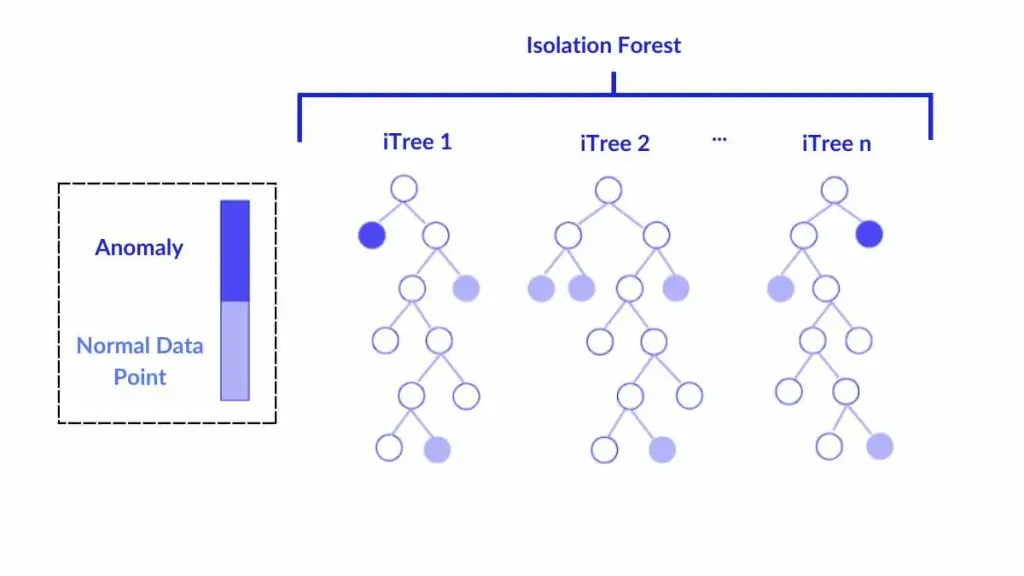

Источник: https://spotintelligence.com/2024/05/21/isolation-forest/.

[Подробнее про изолированный лес.](https://habr.com/ru/companies/otus/articles/881086/)

Обучим Isolation Forest на train и удалим помеченные объекты только из train. Проверим качество классификатора на неизменной validation.

Числовой `contamination` задаёт порог по предполагаемой доле аномалий. Он не сообщает истинную долю ошибок и не меняет правила построения деревьев при фиксированных данных и seed.

Если фильтрация используется перед классификацией, долю удаления подбирают по качеству на отдельной validation. Проверять нужно и вариант без удаления. Здесь используем 1% как заданный учебный параметр.


Построим Isolation Forest по признакам train без целевой переменной. Зададим `contamination=0.01`, чтобы пометить около 1% обучающих объектов как аномалии.

In [ ]:
from sklearn.ensemble import IsolationForest

In [ ]:
numeric

Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm',
       'Temp9am', 'Temp3pm'],
      dtype='object')

In [ ]:
# X_train и X_valid уже преобразованы скейлером, обученным по train.
# Повторно обучать скейлер на всём df не нужно.


In [ ]:
df.head(3)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,RainToday,RainTomorrow,Season_Spring,Season_Summer,Season_Winter
0,13.4,22.9,0.6,5.498277,7.633724,44.0,20.0,24.0,71.0,22.0,...,0,0,0,1,0,0,0,0,1,0
1,7.4,25.1,0.0,5.498277,7.633724,44.0,4.0,22.0,44.0,25.0,...,0,0,0,0,1,0,0,0,1,0
2,12.9,25.7,0.0,5.498277,7.633724,46.0,19.0,26.0,38.0,30.0,...,0,0,0,0,1,0,0,0,1,0


##### Задание 2

- Возьми `X = X_train.copy()` и `y = y_train.copy()`. Validation оставляем неизменной.
- Обучи `IsolationForest` с 300 деревьями, `contamination=0.01`, `random_state=42` и `n_jobs=-1` только на `X`.
- Сохрани в `anomaly_score` значения `-iso.decision_function(X)`. Большие значения означают большую аномальность.
- Сохрани в `labels_outlier` булеву маску `iso.predict(X) == -1`.

Далее фильтруем только train и сравниваем классификаторы на общей validation. Пометка аномалии сама по себе не означает ошибку в наблюдении.


Используй для решения [sklearn Isolation Forest.](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html#)

**Заготовка задания. Решение в следующем кодовом блоке.**

```python
# Напиши код здесь
# X = ...
# y = ...

# iso = IsolationForest(...)

# ...
# anomaly_score = ...
# labels_outlier = ...
```


###### Решение

In [ ]:
X = X_train.copy()
y = y_train.copy()

iso = IsolationForest(
    n_estimators=300,
    contamination=0.01,     # заданная доля помечаемых аномалий
    random_state=42,
    n_jobs=-1,
)
iso.fit(X)
anomaly_score = -iso.decision_function(X)        # чем больше, тем «более аномально»
labels_outlier = (iso.predict(X) == -1)          # True для выбросов

В `anomaly_score` большие значения соответствуют более аномальным объектам. Маска `labels_outlier` отмечает строки train для пробного удаления. Проверим результат фильтрации по ROC-AUC на validation.

Посчитаем число помеченных и оставшихся объектов перед фильтрацией train.

In [ ]:
pd.Series(labels_outlier).value_counts()

False    185249
True       1872
Name: count, dtype: int64

Удалим помеченные наблюдения из train и сравним качество модели до и после фильтрации. Валидационные объекты и их метки оставим прежними.

In [ ]:
X_clean = X.loc[~labels_outlier].copy()
y_clean = y.loc[~labels_outlier].copy()


In [ ]:
# Выводим, сколько аномалий удалили
len(X), len(X_clean)

(187121, 185249)

Повторное разбиение не требуется. Исходный лес обучаем на `X_train`, `y_train`, а второй на их отфильтрованной части. Оба оцениваем на неизменных `X_valid`, `y_valid`. Поэтому сравнение показывает эффект фильтрации train на этой validation.


In [ ]:
X_train_clean, y_train_clean = X_clean, y_clean


Сравним два случайных леса с одинаковыми параметрами: один обучим на исходном train, второй на его отфильтрованной части. При `warm_start=True` увеличим число деревьев по 12 за итерацию и проследим изменение ROC-AUC на общей validation.

In [ ]:
roc_auc_scores_rf_orig = []
roc_auc_scores_rf_clean = []

rf_classifier_orig = RandomForestClassifier(
        n_estimators=12,
        warm_start=True, # Переиспользуем уже обученные деревья
        n_jobs=-1,
        random_state=42)

rf_classifier_clean = RandomForestClassifier(
    n_estimators=12,
    warm_start=True,
    n_jobs=-1,
    random_state=42)

for n in tqdm(range(12, 192, 12)):
    rf_classifier_orig.set_params(n_estimators=n)
    rf_classifier_clean.set_params(n_estimators=n)


    rf_classifier_orig.fit(X_train, y_train)
    y_proba_rf_orig = rf_classifier_orig.predict_proba(X_valid)[:, 1]

    rf_classifier_clean.fit(X_train_clean, y_train_clean)
    y_proba_rf_clean = rf_classifier_clean.predict_proba(X_valid)[:, 1]

    roc_auc_scores_rf_orig.append(roc_auc_score(y_valid, y_proba_rf_orig))
    roc_auc_scores_rf_clean.append(roc_auc_score(y_valid, y_proba_rf_clean))



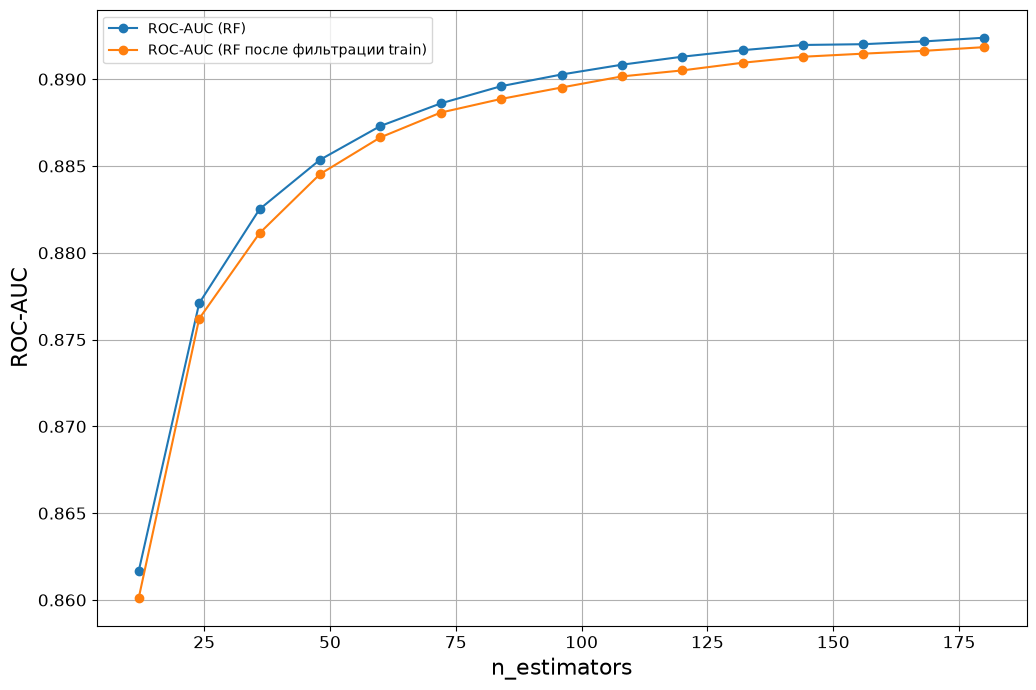

In [ ]:
# Строим график
n_estimator_values = range(12, 192, 12)

plt.figure(figsize=(12, 8))

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.plot(n_estimator_values, roc_auc_scores_rf_orig, label='ROC-AUC (RF)', marker='o', color='tab:blue')
plt.plot(n_estimator_values, roc_auc_scores_rf_clean, label='ROC-AUC (RF после фильтрации train)', marker='o', color='tab:orange')
plt.xlabel('n_estimators', fontsize=16)
plt.ylabel('ROC-AUC', fontsize=16)
plt.legend()
plt.tick_params(axis='y')

plt.grid(True)
plt.show()

**Вопрос.** Какой вывод можно сделать по графику? Что может произойти, если увеличить гиперпараметр `contamination`? Если уменьшить?



**Ответ.** В проверенном запуске кривая RF после фильтрации train немного ниже исходной при каждом проверенном числе деревьев. Удаление объектов здесь не улучшило ROC-AUC на общей validation. Небольшая разница может зависеть от seed и разбиения и не показывает количество ошибочных наблюдений.

При большем contamination удаляется больше train. Это может помочь при вредных наблюдениях или навредить при удалении редких информативных случаев. При меньшем contamination результат приближается к варианту без удаления. Направление изменения качества проверяют по validation.


### Random Forest: `oob_score`

OOB (out-of-bag) использует для каждого объекта train прогнозы только тех деревьев, в бутстрэп которых объект не попал. Не нужно обучать отдельные модели для валидационных фолдов.

В sklearn OOB доступна у поддерживающих её бутстрэп-ансамблей, включая Random Forest, Bagging и Extra Trees при `bootstrap=True`. Она оценивает качество при таком механизме обучения и не заменяет проверку по времени или по новым регионам.

Здесь заполнение пропусков и скейлер обучены на всём train, поэтому OOB не исключает объект из обучения этих преобразований. Внешняя validation остаётся независимой от них.


Обучаем случайный лес с `oob_score=True`, чтобы у него сохранилась информация о предсказаниях для внемешковых наблюдений.

In [ ]:
rf_classifier = RandomForestClassifier(
        n_estimators=100,
        n_jobs=-1,
        oob_score=True,
        random_state=42)

rf_classifier.fit(X_train, y_train)

,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.B

##### Задание 3

Посчитай ROC-AUC по `predict_proba(X_valid)[:, 1]` и по `oob_decision_function_[:, 1]` на train. Атрибут `oob_score_` по умолчанию содержит accuracy, а нам нужны вероятности для ROC-AUC. Убедись, что для всех используемых строк есть OOB-прогноз.


In [ ]:
# Напиши код здесь

# ...
# ...

# print('Валидационная метрика:', ...)
# print('OOB метрика:', ...)

###### Решение

In [ ]:
preds = rf_classifier.predict_proba(X_valid)[:, 1]
oob_proba = rf_classifier.oob_decision_function_
has_oob = np.isfinite(oob_proba).all(axis=1) & (oob_proba.sum(axis=1) > 0)
print('Доля train с OOB-прогнозом:', has_oob.mean())
print('ROC-AUC на validation:', roc_auc_score(y_valid, preds))
print('OOB ROC-AUC:', roc_auc_score(y_train.iloc[np.flatnonzero(has_oob)], oob_proba[has_oob, 1]))


Доля train с OOB-прогнозом: 1.0
ROC-AUC на validation: 0.8905043638923618
OOB ROC-AUC: 0.8815793906881217


Сравни OOB ROC-AUC и ROC-AUC на validation. Они рассчитаны на разных объектах и разным числом деревьев на объект. Расхождение одного опыта не устанавливает систематическое завышение или занижение OOB. При небольшом числе деревьев проверь долю объектов с OOB-прогнозом.


### Random Forest: важность признаков

Для неглубокого дерева можно проследить путь объекта от корня до листа. В большом ансамбле такое объяснение сложнее. Оценки важности признаков помогают описать, какие признаки использует модель, но не устанавливают причинное влияние этих признаков на целевую переменную.

Рассмотрим MDI и permutation importance, затем кратко обсудим SHAP.

**MDI** (Mean Decrease in Impurity) суммирует уменьшения неопределённости в разбиениях по каждому признаку. В формулах $H(R)$ обозначает критерий неопределённости в узле с объектами $R$, например Gini. $R_\ell$ и $R_r$ обозначают левую и правую части после разбиения, а $|R|$ число объектов. Ниже приведены формулы для наблюдений с одинаковыми весами. При `sample_weight` или весах классов вместо числа объектов используются суммы весов.


$$\Delta H(R, j, t) = H(R) - \left (\frac{|R_\ell|}{|R|} H(R_\ell) + \frac{|R_r|}{|R|} H(R_r)\right),$$

$$\mathrm{MDI}_j^{\mathrm{tree}}
= \sum_{t:\,\text{split on } j}
\frac{\lvert R_t\rvert}{\lvert R\rvert}\;\Delta H(R_t, j, t),$$

Для дерева сырые вклады нормируются на их сумму по признакам. Лес усредняет такие нормированные важности по деревьям и нормирует результат. Поэтому sklearn обычно возвращает вектор с суммой 1. Если во всём ансамбле нет разбиений, важности нулевые.

$$\mathrm{MDI}_j^{\mathrm{forest}}\ \propto\ \frac1T\sum_{k=1}^T
\frac{\mathrm{MDI}_j^{\mathrm{tree}\,k}}{\sum_l\mathrm{MDI}_l^{\mathrm{tree}\,k}}.$$

В этой записи деревья без разбиений дают нулевой вклад. $R_t$ в предыдущей формуле обозначает область узла, $R$ всю обучающую область, $T$ число деревьев.


MDI быстрый, но имеет ограничения: он склонен завышать важность признаков с большим количеством уникальных значений и может давать смещённые оценки при коррелированных фичах.

>**MDA** (англ. Mean Decrease in Accuracy), или permutation importance, оценивает важность признака по изменению качества модели при случайной перестановке значений этого признака в валидационных данных.

Если перестановка заметно ухудшает метрику (например, ROC-AUC или accuracy), признак считается важным:

Для метрики $S$, которую нужно максимизировать (например, ROC-AUC), важность равна падению метрики:
$$I_j = S(y, \hat f(X)) - S(y, \hat f(X_{\mathrm{perm},j})).$$
Для ошибки, которую нужно минимизировать (например, MSE), меняется порядок вычитания:
$$I_j = \mathrm{Err}(y, \hat f(X_{\mathrm{perm},j})) - \mathrm{Err}(y, \hat f(X)).$$

Иногда увеличение ошибки делят на исходную ошибку:
$$I_j^{\mathrm{rel}} = \frac{\mathrm{Err}_{\mathrm{perm},j}-\mathrm{Err}_{\mathrm{base}}}{\mathrm{Err}_{\mathrm{base}}}.$$
Такая относительная величина определена только при ненулевой исходной ошибке. `permutation_importance` ниже возвращает абсолютное падение ROC-AUC без этой нормировки.

Для $R$ перестановок sklearn усредняет падение метрики всего ансамбля:
$$I_j^{\mathrm{forest}} = \frac1R\sum_{r=1}^R\bigl(S_{\mathrm{base}}-S_{\mathrm{perm},j}^{(r)}\bigr).$$
Здесь $R$ обозначает число повторов. Ансамбль при оценке не переобучается.

Permutation importance требует нескольких оценок уже обученной модели. Использование validation уменьшает влияние подгонки train и не даёт предпочтения числовому признаку только из-за большого числа возможных порогов.

При коррелированных признаках другой столбец может заменять перемешанный, поэтому индивидуальная важность бывает маленькой у полезного признака. Оба метода нужно интерпретировать с учётом зависимостей между признаками.


> **SHAP** распределяет разность между прогнозом для объекта и базовым значением по признакам с помощью значений Шепли. Вклад признака усредняется по разным наборам остальных признаков.

Результат зависит от того, как задаются значения отсутствующих признаков и учитываются их зависимости. Средние абсолютные вклады по объектам можно использовать для общего описания модели. Здесь ограничимся этим обзором. [Документация TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).

MDI характеризует разбиения обученных деревьев. Permutation importance измеряет изменение выбранной метрики при перемешивании признака. SHAP разбирает вклад признаков в отдельный прогноз. Это разные вопросы, поэтому одинакового ранжирования ждать не нужно. В этом семинаре считаем MDI и permutation importance, а SHAP оставляем обзором.


#### sklearn `feature_importances_` (MDI)


MDI (Mean Decrease in Impurity) показывает, насколько признаки в среднем уменьшают критерий (Gini или entropy) внутри деревьев.

In [ ]:
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    n_jobs=-1,
    random_state=42,
)
rf_classifier.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

In [ ]:
rf_classifier.feature_importances_

array([0.04262588, 0.04185195, 0.05352304, 0.02379326, 0.04424866,
       0.04890295, 0.0277217 , 0.02952128, 0.05321927, 0.14132785,
       0.04688612, 0.05300328, 0.02415696, 0.03748549, 0.03963826,
       0.0438587 , 0.02705399, 0.00127949, 0.00134776, 0.00053966,
       0.00126498, 0.00133788, 0.00106836, 0.00128473, 0.00103111,
       0.00126079, 0.00080154, 0.00167005, 0.00119583, 0.00075552,
       0.00101193, 0.00147191, 0.00026339, 0.00098574, 0.00125973,
       0.00123201, 0.00084256, 0.00082561, 0.00141976, 0.00087441,
       0.00052428, 0.0010174 , 0.00139704, 0.00160465, 0.00125352,
       0.00121869, 0.00090238, 0.0016346 , 0.00136351, 0.00152913,
       0.00116201, 0.00112615, 0.00092483, 0.0016665 , 0.00139958,
       0.00066363, 0.00133125, 0.00045061, 0.00115399, 0.00197179,
       0.00134201, 0.0015012 , 0.00213446, 0.0013932 , 0.00080714,
       0.00220836, 0.00214667, 0.00325505, 0.00266186, 0.0027246 ,
       0.00273393, 0.00312158, 0.00295791, 0.0026609 , 0.00248

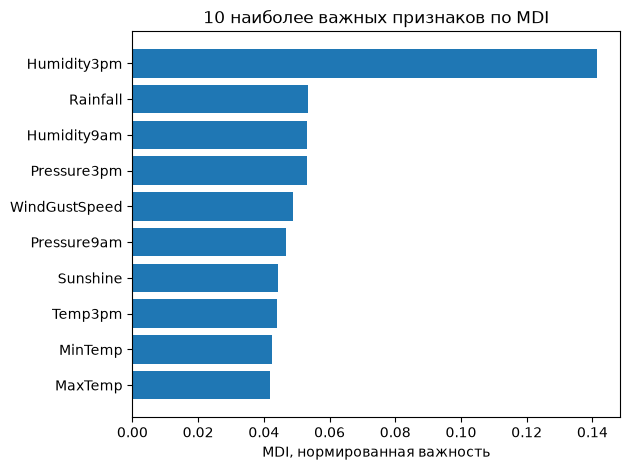

In [ ]:
fi = pd.DataFrame({'column': X_train.columns, 'feature_importance': rf_classifier.feature_importances_})
fi = fi.sort_values('feature_importance', ascending=True).tail(10)
plt.barh(fi['column'], fi['feature_importance'])
plt.xlabel('MDI, нормированная важность')
plt.title('10 наиболее важных признаков по MDI')
plt.tight_layout()
plt.show()


Прочитай порядок признаков по графику. MDI показывает нормированное уменьшение неопределённости в деревьях. Признаки с большим числом возможных разбиений могут получать завышенную важность. Из этого графика нельзя вывести причинное влияние признака на дождь.


#### Перестановки (MDA)

Измерим падение ROC-AUC при перемешивании одного столбца в validation. Это permutation importance. Модель при перестановках не переобучается.


In [ ]:
from sklearn.inspection import permutation_importance

In [ ]:
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    n_jobs=-1,
    random_state=42,
)
rf_classifier.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

Для permutation importance возьмём 500 объектов из validation с фиксированным seed. Это уменьшает время расчёта, но оценки могут сильнее зависеть от выбранной подвыборки.

In [ ]:
X_sample = X_valid.sample(500, random_state=42)
y_sample = y_valid.loc[X_sample.index]

Считаем permutation importance: 10 перестановок на признак, метрика ROC-AUC. `perm.importances_mean` содержит среднее падение метрики, `perm.importances_std` разброс по перестановкам.


In [ ]:
perm = permutation_importance(
    rf_classifier, X_sample, y_sample,
    n_repeats=10,
    #n_jobs=-1,
    random_state=42,
    scoring="roc_auc")

Большая положительная permutation importance означает заметное падение ROC-AUC при перемешивании. Значение около нуля может соответствовать слабому влиянию или замене признака коррелированными столбцами. Отрицательное значение может возникнуть из-за случайных перестановок и не доказывает, что признак вреден. Сопоставь среднее с разбросом по повторам.


In [ ]:
perm.importances_mean

array([ 1.98058390e-03,  8.01327475e-03,  1.23405612e-02,  1.15870654e-02,
        1.82716837e-02,  1.80650038e-02,  6.10473356e-03,  8.57426304e-04,
        1.41817838e-02,  6.52671485e-02,  1.17571334e-02,  1.72075775e-02,
        2.76596750e-03,  1.34826153e-02,  3.93400416e-03,  1.68355537e-02,
        3.88794407e-03,  4.39342404e-04, -1.19283825e-04,  1.25188964e-04,
       -8.73960695e-05,  6.96806500e-05,  1.18102797e-03,  1.63690476e-03,
       -3.51946334e-04,  6.22401738e-04, -9.68442933e-05,  2.22033258e-04,
        3.46041194e-04,  2.63369237e-04,  2.37386621e-04,  1.19401927e-03,
        5.66893424e-05, -5.77522676e-04,  3.89739229e-05, -4.10997732e-04,
        1.39125094e-03,  1.38180272e-04, -8.62150416e-05, -1.57076720e-04,
       -2.19671202e-04, -1.73611111e-04,  6.21220711e-04,  5.42091837e-04,
        7.21608088e-04,  2.30300454e-04,  3.20058579e-04,  1.32511338e-03,
        6.73185941e-05, -1.06292517e-05, -8.97581255e-05,  1.11252834e-03,
       -1.09835601e-04,  

Построим столбчатый график десяти признаков с наибольшим средним падением ROC-AUC. Полосы покажут стандартное отклонение по перестановкам.

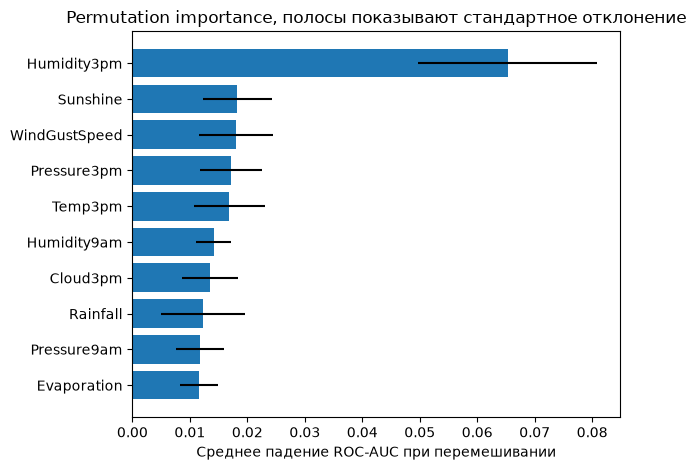

In [ ]:
fi = pd.DataFrame({'column': X_train.columns, 'feature_importance': perm.importances_mean,
                   'std': perm.importances_std})
fi = fi.sort_values('feature_importance').tail(10)
plt.barh(fi['column'], fi['feature_importance'], xerr=fi['std'])
plt.xlabel('Среднее падение ROC-AUC при перемешивании')
plt.title('Permutation importance, полосы показывают стандартное отклонение')
plt.tight_layout()
plt.show()


В проверочном запуске на 500 объектах наибольшее среднее падение ROC-AUC даёт перемешивание `Humidity3pm`, около 0.065. Далее идут `Sunshine` и `WindGustSpeed`, около 0.018. Сравни значения и полосы разброса на графике.

Permutation importance измеряет изменение выбранной метрики на этой подвыборке. Порядок признаков может меняться с выборкой и seed, особенно при близких значениях и связанных признаках.

MDI основана на обучающих разбиениях, permutation importance на изменении валидационной метрики при вмешательстве в один столбец. Сравни ранжирование и разброс permutation importance. Ни одна оценка не является причинной значимостью признака. Для отбора признаков потребуется отдельно проверить качество модели после отбора.


### Extra Trees

**Extra Trees** случайно генерирует пороги для выбранных признаков и выбирает лучший из этих кандидатов по критерию разбиения. Random Forest ищет лучший допустимый порог среди значений признака.

Дополнительная рандомизация меняет силу и сходство деревьев. Она может ускорить обучение, но итоговое качество зависит от данных и параметров. Для следующего сравнения в обоих ансамблях используем бутстрэп. По умолчанию у Extra Trees `bootstrap=False`.


In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

Сравним Random Forest и Extra Trees на одной validation. На каждом шаге добавим по 12 деревьев и измерим ROC-AUC и суммарное время обучения новых деревьев и прогнозирования.

In [ ]:
# Рассчитать до занятия, время зависит от среды.
roc_auc_scores_rf = []
train_predict_times_rf = []
roc_auc_scores_extra = []
train_predict_times_extra = []

extra_classifier = ExtraTreesClassifier(
        n_estimators=12,
        warm_start=True, # Переиспользуем уже обученные деревья
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    )

rf_classifier = RandomForestClassifier(
    n_estimators=12,
    warm_start=True,
    n_jobs=-1,
    random_state=42)

for n in tqdm(range(12, 192, 12)):
    extra_classifier.set_params(n_estimators=n)
    rf_classifier.set_params(n_estimators=n)


    start_time_extra = time()
    extra_classifier.fit(X_train, y_train)
    y_proba_extra = extra_classifier.predict_proba(X_valid)[:, 1]
    end_time_extra = time()

    start_time_rf = time()
    rf_classifier.fit(X_train, y_train)
    y_proba_rf = rf_classifier.predict_proba(X_valid)[:, 1]
    end_time_rf = time()

    roc_auc_scores_extra.append(roc_auc_score(y_valid, y_proba_extra))
    train_predict_times_extra.append(end_time_extra - start_time_extra)

    roc_auc_scores_rf.append(roc_auc_score(y_valid, y_proba_rf))
    train_predict_times_rf.append(end_time_rf - start_time_rf)



Изобразим зависимость ROC-AUC и времени обучения/предсказания обоих ансамблей от `n_estimators` на графике.

Локальная проверка: 6 рабочих процессов. Сравнивайте время внутри графика. Для сравнения времени между графиками нужна одинаковая среда.


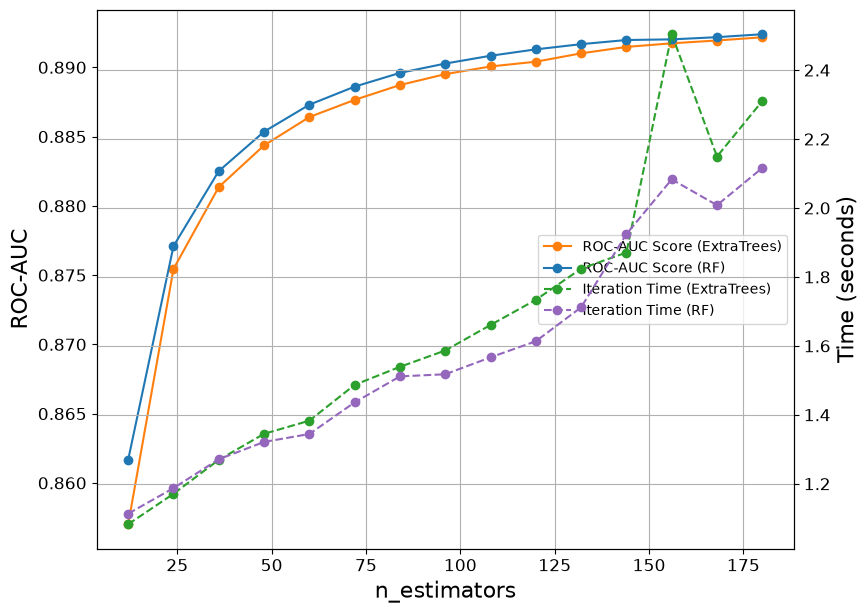

In [ ]:
# Строим график
n_estimators_values = list(range(12, 192, 12))

plt.figure(figsize=(9, 7))

ax1 = plt.gca()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax1.plot(n_estimators_values, roc_auc_scores_extra, label='ROC-AUC Score (ExtraTrees)', marker='o', color='tab:orange')
ax1.plot(n_estimators_values, roc_auc_scores_rf, label='ROC-AUC Score (RF)', marker='o', color='tab:blue')
ax1.set_xlabel('n_estimators', fontsize=16)
ax1.set_ylabel('ROC-AUC', fontsize=16)
ax1.tick_params(axis='y')
plt.grid(axis='x')

ax2 = ax1.twinx()
plt.yticks(fontsize=12)

ax2.plot(n_estimators_values, train_predict_times_extra, label='Iteration Time (ExtraTrees)',
         linestyle='dashed', marker='o', color='tab:green')
ax2.plot(n_estimators_values, train_predict_times_rf, label='Iteration Time (RF)',
         linestyle='dashed', marker='o', color='tab:purple')


ax2.set_ylabel('Time (seconds)', fontsize=16)

ax2.tick_params(axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.grid()
plt.show()

### Cравнение Random Forest и Extra Trees

Сравни ROC-AUC при одинаковом числе деревьев. Результат относится к заданным параметрам и разбиению. Extra Trees выбирает лучший среди случайно сгенерированных кандидатов, поэтому его разбиения также зависят от таргета.


Показанное время включает обучение добавленных деревьев и прогнозирование всем ансамблем. Оно не позволяет отдельно измерить стоимость поиска порогов. На соотношение времени влияют данные, глубины деревьев, параллелизм и параметры.


Выбери подходящий вариант по валидационному ROC-AUC и измеренному времени. В этом опыте у обоих ансамблей включён бутстрэп. Сравнение с Extra Trees по умолчанию было бы отдельным опытом.


## Ключевые характеристики ансамблей

- Бэггинг объединяет модели на бутстрэп-выборках и особенно полезен для неустойчивых базисов.
- Random Forest добавляет случайный набор признаков на каждом разбиении дерева.
- Isolation Forest ранжирует необычность объектов. Фильтрацию train проверяют по качеству последующей модели на неизменной validation.
- OOB использует прогнозы деревьев, которые не обучались на соответствующем объекте.
- MDI и permutation importance измеряют разные свойства модели и зависят от связей между признаками.
- Extra Trees выбирает разбиения среди случайных порогов. Качество и время сравнивают экспериментально.


## Что отработали на семинаре

- Обучение бэггинга и случайного леса в sklearn.
- Сравнение гиперпараметров по ROC-AUC и времени вычислений.
- Фильтрацию train с помощью Isolation Forest и проверку её результата.
- Расчёт OOB ROC-AUC, MDI и permutation importance.

# Обратная связь по семинару

Пройди короткий опрос по [ссылке](https://forms.gle/M65heFJf1Vv9AXMp6) или QR-коду ниже.

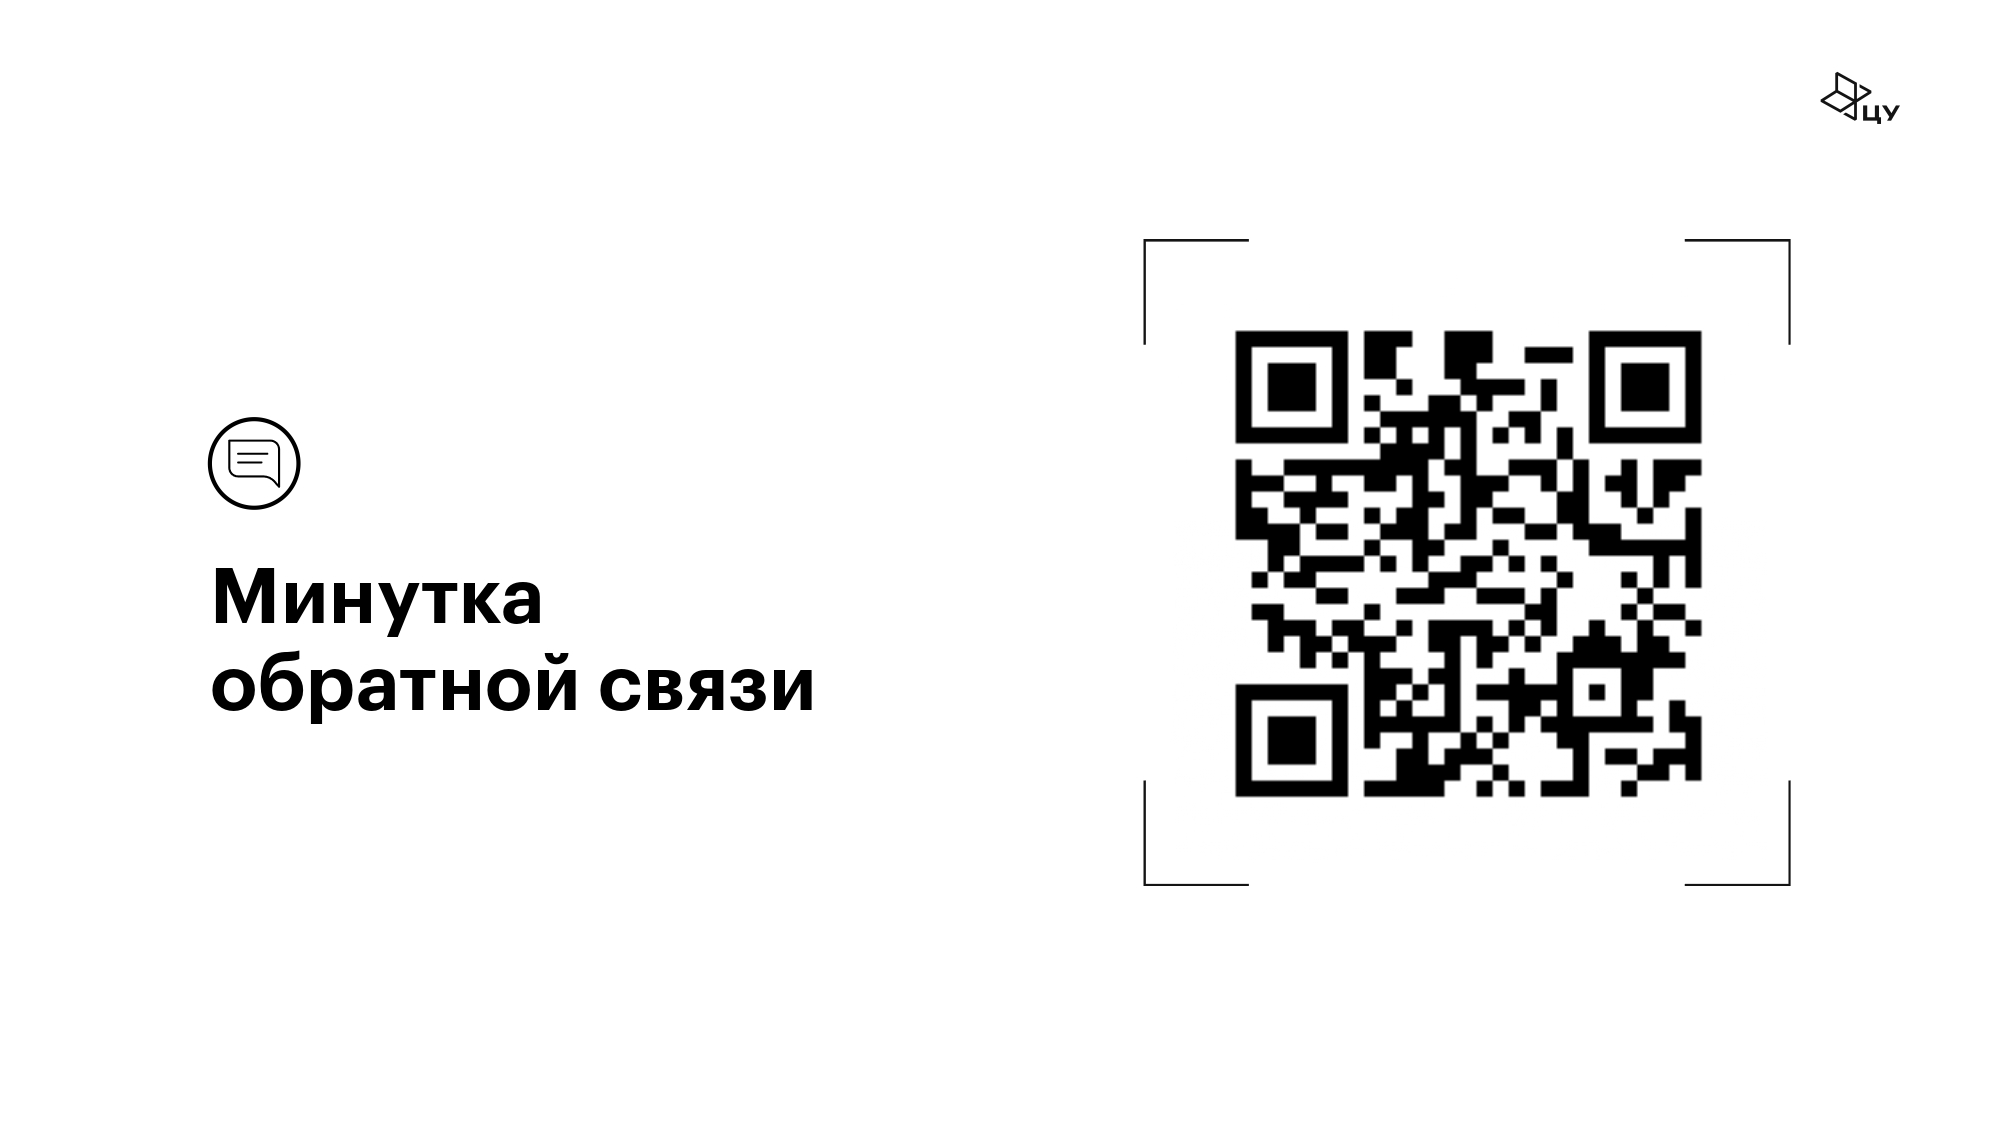